# Chromatin accessibility analysis and figures

Run top to bottom using the restored R environment. Inputs: `arrow_files/` and `reference/`. Outputs: `output/figures/`, `output/tables/` and `output/logs/`. See `README.md` for the Arrow and fragment starting points. Saved notebook outputs are from the original run, before this path and naming cleanup.


In [1]:
# Load renv
if (!exists("project_dir", inherits = FALSE)) project_dir <- normalizePath(Sys.getenv("ARCHR_PROJECT_DIR", unset = getwd()))
Sys.setenv(RENV_PATHS_SANDBOX = file.path(project_dir, "renv", "sandbox"))
renv::load(project = project_dir)

library(ArchR)
library(GenomicRanges)
library(rtracklayer)
library(BSgenome)
library(ggplot2)
library(patchwork)
library(MASS)


- The project is out-of-sync -- use `renv::status()` for details.



                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .______      
          /   \     |   _ 

In [2]:
# Input and output folders
arrow_files <- setNames(file.path(project_dir, "arrow_files", c("HFD.arrow", "LFD.arrow")), c("HFD", "LFD"))
reference_dir <- file.path(project_dir, "reference")
output_dir <- file.path(project_dir, "output")
figure_dir <- file.path(output_dir, "figures")
tables_dir <- file.path(output_dir, "tables")
log_dir <- file.path(output_dir, "logs")
for (folder in c(figure_dir, tables_dir, log_dir)) dir.create(folder, recursive = TRUE, showWarnings = FALSE)

# Save each figure
save_plot <- function(plot, name, folder, width = 10, height = 8) {
    dir.create(folder, recursive = TRUE, showWarnings = FALSE)
    for (extension in c("png", "svg", "pdf")) {
        device <- switch(extension, png = "png", svg = svglite::svglite, pdf = cairo_pdf)
        ggsave(file.path(folder, paste0(name, ".", extension)), plot, device = device,
            width = width, height = height, units = "in", dpi = 180, bg = "white")
    }
}

runtime_parent <- if (grepl(" ", output_dir, fixed = TRUE)) tempdir() else output_dir
runtime_dir <- tempfile("ArchR_", tmpdir = runtime_parent)
dir.create(runtime_dir)
setwd(runtime_dir)
options(ArchR.genome = NULL)
addArchRThreads(threads = 1)


Setting default number of Parallel threads to 1.



## Create the project


In [3]:
# mm39 annotation from the Cell Ranger filtered GTF
mm39 <- BSgenome::getBSgenome("BSgenome.Mmusculus.UCSC.mm39")
chromosomes <- c(paste0("chr", 1:19), "chrX", "chrY")
mm39_seqinfo <- seqinfo(mm39)[chromosomes]
genome(mm39_seqinfo) <- "mm39"
standardize <- function(gr) {
    gr <- keepSeqlevels(gr, intersect(seqlevels(gr), chromosomes), pruning.mode = "coarse")
    seqinfo(gr) <- mm39_seqinfo[seqlevels(gr)]
    gr
}
gtf <- standardize(import(file.path(reference_dir, "genes.gtf.gz")))
genes <- gtf[gtf$type == "gene"]
genes$symbol <- genes$gene_name
transcript_annotation <- gtf[gtf$type == "transcript"]
exon_groups <- reduce(split(gtf[gtf$type == "exon"], gtf$gene_id[gtf$type == "exon"]))
exons <- unlist(exon_groups, use.names = FALSE)
exons$gene_id <- rep(names(exon_groups), lengths(exon_groups))
exons$symbol <- genes$symbol[match(exons$gene_id, genes$gene_id)]
gene_annotation <- createGeneAnnotation(genes = genes, exons = exons,
    TSS = resize(transcript_annotation, width = 1, fix = "start"))
blacklist <- standardize(import(file.path(reference_dir, "blacklist.bed")))
genome_annotation <- createGenomeAnnotation(genome = mm39, blacklist = blacklist,
    chromSizes = GRanges(chromosomes, IRanges(1, seqlengths(mm39_seqinfo)), seqinfo = mm39_seqinfo))

proj <- ArchRProject(ArrowFiles = arrow_files, outputDirectory = runtime_dir,
    geneAnnotation = gene_annotation, genomeAnnotation = genome_annotation, copyArrows = FALSE)
rm(gtf, exon_groups)
table(proj$Sample)


Getting genome..

Using provided chromSizes..

Using provided blacklist...

Validating Arrows...

Getting SampleNames...

1 
2 


Getting Cell Metadata...

1 
2 


Merging Cell Metadata...

Initializing ArchRProject...


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   


 HFD  LFD 
3324 3087 

## Calculate LSI, clusters and UMAP


Resolution of 4 for addClusters gave us the required details to investigate the clusters enriched in HFD vs LFD.

In [4]:
RNGkind("L'Ecuyer-CMRG", "Inversion", "Rejection")
set.seed(1)
addArchRThreads(threads = 6L)
proj <- addIterativeLSI(
    ArchRProj = proj, useMatrix = "TileMatrix", name = "IterativeLSI", iterations = 2,
    clusterParams = list(resolution = c(2), sampleCells = 10000, maxClusters = 6, n.start = 10),
    firstSelection = "top", depthCol = "nFrags", varFeatures = 25000, dimsToUse = 1:30,
    LSIMethod = 2, scaleDims = TRUE, corCutOff = 0.75, binarize = TRUE,
    outlierQuantiles = c(0.02, 0.98), filterBias = TRUE, sampleCellsPre = 10000,
    projectCellsPre = FALSE, sampleCellsFinal = NULL, selectionMethod = "var",
    scaleTo = 10000, totalFeatures = 500000, filterQuantile = 0.995,
    excludeChr = c(), keep0lsi = FALSE, saveIterations = TRUE,
    UMAPParams = list(n_neighbors = 40, min_dist = 0.4, metric = "cosine",
        verbose = FALSE, fast_sgd = TRUE), nPlot = 10000,
    threads = 6L, seed = 1, force = TRUE,
    logFile = file.path(log_dir, "recompute_IterativeLSI.log"))

RNGkind("Mersenne-Twister", "Inversion", "Rejection")
addArchRThreads(threads = 1)
proj <- addClusters(input = proj, reducedDims = "IterativeLSI", method = "Seurat",
    name = "Clusters", resolution = 4, maxClusters = 50, filterBias = FALSE,
    seed = 1, force = TRUE, logFile = file.path(log_dir, "recompute_resolution4.log"))
proj <- addUMAP(ArchRProj = proj, reducedDims = "IterativeLSI", name = "UMAP",
    nNeighbors = 40, minDist = 0.4, metric = "cosine", seed = 1, threads = 1, force = TRUE)


Setting default number of Parallel threads to 6.

Checking Inputs...

ArchR logging to : output/logs/recompute_IterativeLSI.log
If there is an issue, please report to github with logFile!

2026-10-25 16:36:20.695169 : Computing Total Across All Features, 0.003 mins elapsed.

2026-10-25 16:36:21.393516 : Computing Top Features, 0.014 mins elapsed.

###########
2026-10-25 16:36:22.356808 : Running LSI (1 of 2) on Top Features, 0.03 mins elapsed.
###########

2026-10-25 16:36:22.438899 : Creating Partial Matrix, 0.032 mins elapsed.

2026-10-25 16:36:33.431035 : Computing LSI, 0.215 mins elapsed.

Filtering 1 dims correlated > 0.75 to log10(depth + 1)

2026-10-25 16:36:44.133762 : Identifying Clusters, 0.393 mins elapsed.

2026-10-25 16:36:50.714581 : Identified 6 Clusters, 0.503 mins elapsed.

2026-10-25 16:36:50.723637 : Saving LSI Iteration, 0.503 mins elapsed.

2026-10-25 16:37:00.170688 : Creating Cluster Matrix on the total Group Features, 0.661 mins elapsed.

2026-10-25 16:37:36.874

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 6411
Number of edges: 237196

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6655
Number of communities: 33
Elapsed time: 0 seconds


2026-10-25 16:38:00.514436 : Testing Biased Clusters, 0.083 mins elapsed.

2026-10-25 16:38:00.523522 : Testing Outlier Clusters, 0.084 mins elapsed.

2026-10-25 16:38:00.525758 : Assigning Cluster Names to 33 Clusters, 0.084 mins elapsed.

2026-10-25 16:38:00.565424 : Finished addClusters, 0.084 mins elapsed.

16:38:00 UMAP embedding parameters a = 0.7669 b = 1.223

16:38:00 Read 6411 rows and found 30 numeric columns

16:38:00 Using Annoy for neighbor search, n_neighbors = 40

16:38:00 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:38:01 Writing NN index file to temp file /var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T//RtmpdD15kB/file1e725e1b2ec

16:38:01 Searching Annoy index using 4 threads, search_k = 4000

16:38:01 Annoy recall = 100%

16:38:02 Commencing s

Length of unique values greater than palette, interpolating..



     
      HFD LFD
  C1   57  34
  C2  133  68
  C3   49  94
  C4  138  72
  C5   83  99
  C6   23  26
  C7  119 148
  C8  222  43
  C9  157 116
  C10  64 178
  C11  70 158
  C12  96 145
  C13  67  83
  C14  63  99
  C15 130  59
  C16  56  46
  C17  36  53
  C18 115 111
  C19 140 137
  C20  83 107
  C21  81   9
  C22 194  42
  C23  65 147
  C24  21 114
  C25 208  57
  C26  92 123
  C27 195  30
  C28 210  18
  C29 121   4
  C30  31  91
  C31  35 260
  C32 107 114
  C33  63 202

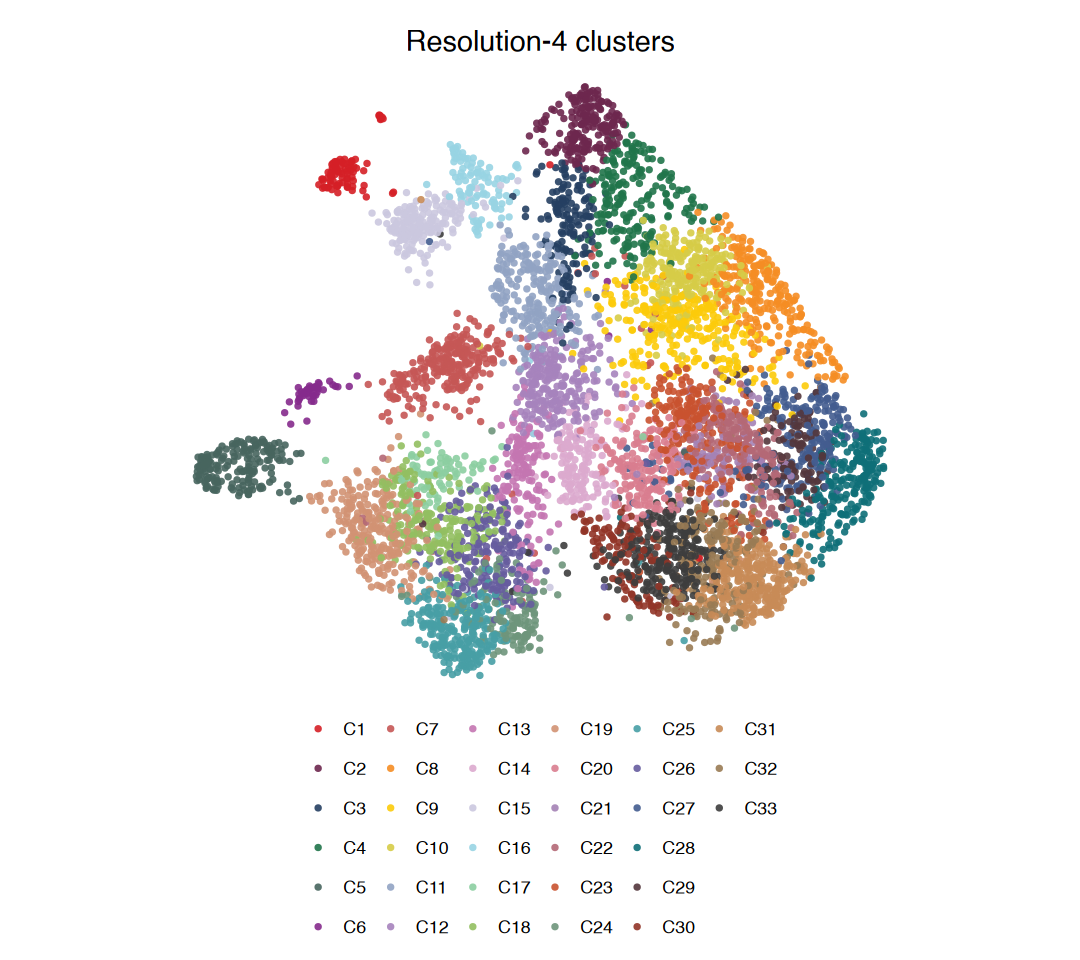

In [5]:
# UMAP
embedding <- getEmbedding(proj, "UMAP", returnDF = TRUE)
umap_df <- data.frame(cell_id = getCellNames(proj), Sample = as.character(proj$Sample),
    Resolution4Cluster = as.character(proj$Clusters), UMAP1 = embedding[, 1], UMAP2 = embedding[, 2])
umap_df$Resolution4Cluster <- factor(umap_df$Resolution4Cluster, levels = paste0("C", 1:33))
umap_theme <- theme_void(base_size = 13) + theme(
    plot.title = element_text(size = 17, hjust = 0.5), legend.position = "bottom",
    legend.title = element_blank(), plot.margin = margin(4, 4, 4, 4, unit = "mm"))
set.seed(42)
plot_order <- sample(seq_len(nrow(umap_df)))
p_clusters <- ggplot(umap_df[plot_order, ], aes(UMAP1, UMAP2, colour = Resolution4Cluster)) +
    geom_point(size = 1.8, alpha = 0.9, stroke = 0) + coord_equal() + umap_theme +
    scale_colour_manual(values = paletteDiscrete(paste0("C", 1:33), set = "stallion")) +
    guides(colour = guide_legend(ncol = 6)) + labs(title = "Resolution-4 clusters")
options(repr.plot.width = 9, repr.plot.height = 8)
print(p_clusters)
save_plot(p_clusters, "Resolution4_clusters", file.path(figure_dir, "umap"), 9, 8)
table(umap_df$Resolution4Cluster, umap_df$Sample)


## Calculate top markers per cluster

Calculate markers from the GeneScoreMatrix for the 33 clusters before merging.


In [6]:
# Keep the original cluster labels
proj$Resolution4Cluster <- as.character(
    umap_df$Resolution4Cluster[match(getCellNames(proj), umap_df$cell_id)])
stopifnot(!anyNA(proj$Resolution4Cluster))

set.seed(42)
markers <- getMarkerFeatures(
    ArchRProj = proj,
    useMatrix = "GeneScoreMatrix",
    groupBy = "Resolution4Cluster",
    testMethod = "wilcoxon",
    bias = c("TSSEnrichment", "log10(nFrags)"),
    threads = 1,
    logFile = file.path(log_dir, "markers_before_merging.log"))
genes_all_clusters <- getMarkers(markers, cutOff = "FDR <= 1")


ArchR logging to : output/logs/markers_before_merging.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2026-10-25 16:38:09.761657 : Matching Known Biases, 0.002 mins elapsed.

2026-10-25 16:38:11.534401 : Computing Pairwise Tests (1 of 33), 0.032 mins elapsed.

Pairwise Test C1 : Seqnames chr1

Pairwise Test C1 : Seqnames chr10

Pairwise Test C1 : Seqnames chr11

Pairwise Test C1 : Seqnames chr12

Pairwise Test C1 : Seqnames chr13

Pairwise Test C1 : Seqnames chr14

Pairwise Test C1 : Seqnames chr15

Pairwise Test C1 : Seqnames chr16

Pairwise Test C1 : Seqnames chr17

Pairwise Test C1 : Seqnames chr18

Pairwise Test C1 : Seqnames chr19

Pairwise Test C1 : Seqnames chr2

Pairwise Test C1 : Seqnames chr3

Pairwise Test C1 : Seqnames chr4

Pairwise Test C1 : Seqnames chr5

Pairwise Test C1 : Seqnames chr6

Pairwise Test C1 : Seqnames chr7

Pairwise Test C1 : Seqnames chr8

Pairwise Test C1 : Seqnames chr9

Pairwise Test C1 : Seqnames ch

In [7]:
# Save significant markers per cluster
marker_dir <- file.path(tables_dir, "markers_before_merging")
cluster_marker_dir <- file.path(marker_dir, "per_cluster")
dir.create(cluster_marker_dir, recursive = TRUE, showWarnings = FALSE)

for (cluster in names(genes_all_clusters)) {
    cluster_data <- as.data.frame(genes_all_clusters[[cluster]])
    genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05, , drop = FALSE]
    write.csv(genes_clusters_sig,
        file.path(cluster_marker_dir, paste0(cluster, "_significant_genes.csv")),
        row.names = FALSE)
    message(cluster, ": ", nrow(genes_clusters_sig), " significant genes")
}


C1: 3274 significant genes

C2: 8023 significant genes

C3: 2 significant genes

C4: 846 significant genes

C5: 4456 significant genes

C6: 0 significant genes

C7: 192 significant genes

C8: 1015 significant genes

C9: 62 significant genes

C10: 17 significant genes

C11: 847 significant genes

C12: 785 significant genes

C13: 645 significant genes

C14: 718 significant genes

C15: 7677 significant genes

C16: 3443 significant genes

C17: 43 significant genes

C18: 1718 significant genes

C19: 2901 significant genes

C20: 106 significant genes

C21: 3 significant genes

C22: 787 significant genes

C23: 59 significant genes

C24: 598 significant genes

C25: 2951 significant genes

C26: 1347 significant genes

C27: 1175 significant genes

C28: 1596 significant genes

C29: 25 significant genes

C30: 145 significant genes

C31: 1614 significant genes

C32: 828 significant genes

C33: 2985 significant genes



Top markers HFD vs LFD


In [8]:
set.seed(42)
markers_condition <- getMarkerFeatures(
    ArchRProj = proj,
    useMatrix = "GeneScoreMatrix",
    groupBy = "Sample",
    testMethod = "wilcoxon",
    bias = c("TSSEnrichment", "log10(nFrags)"),
    threads = 1,
    logFile = file.path(log_dir, "markers_HFD_vs_LFD.log"))
top_genes_per_sample <- getMarkers(markers_condition, cutOff = "FDR <= 1")

condition_marker_dir <- file.path(marker_dir, "per_condition")
dir.create(condition_marker_dir, recursive = TRUE, showWarnings = FALSE)
for (sample in names(top_genes_per_sample)) {
    sample_data <- as.data.frame(top_genes_per_sample[[sample]])
    genes_sample_sig <- sample_data[
        sample_data$FDR < 0.05 & sample_data$Log2FC > 1, , drop = FALSE]
    write.csv(genes_sample_sig,
        file.path(condition_marker_dir, paste0(sample, "_significant_genes.csv")),
        row.names = FALSE)
    message(sample, ": ", nrow(genes_sample_sig), " significant genes")
}


ArchR logging to : output/logs/markers_HFD_vs_LFD.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2026-10-25 16:46:41.651821 : Matching Known Biases, 0.002 mins elapsed.

2026-10-25 16:46:42.192066 : Computing Pairwise Tests (1 of 2), 0.011 mins elapsed.

Pairwise Test HFD : Seqnames chr1

Pairwise Test HFD : Seqnames chr10

Pairwise Test HFD : Seqnames chr11

Pairwise Test HFD : Seqnames chr12

Pairwise Test HFD : Seqnames chr13

Pairwise Test HFD : Seqnames chr14

Pairwise Test HFD : Seqnames chr15

Pairwise Test HFD : Seqnames chr16

Pairwise Test HFD : Seqnames chr17

Pairwise Test HFD : Seqnames chr18

Pairwise Test HFD : Seqnames chr19

Pairwise Test HFD : Seqnames chr2

Pairwise Test HFD : Seqnames chr3

Pairwise Test HFD : Seqnames chr4

Pairwise Test HFD : Seqnames chr5

Pairwise Test HFD : Seqnames chr6

Pairwise Test HFD : Seqnames chr7

Pairwise Test HFD : Seqnames chr8

Pairwise Test HFD : Seqnames chr9

Pairwise Test HF

## Cluster identification

Imputed gene scores for the marker lists, with an individual colour scale for each gene.


In [9]:
markerGenes <- c(
    "Cd69", "Gata3", "Foxp3", "Tbx21", "Rorc", "Nr1d1", "Il2", "Stat3",
    "Irf4", "Cd44", "Sell", "Il17a", "Il17f", "Il22", "Il21", "Il23r",
    "Il1r1", "Ikzf2", "Icos", "Il1r2", "Tox", "Pparg", "Rora", "Il19",
    "Il1rl1", "Il7r", "Il2ra", "Ifng", "Cat", "S1pr1", "Bcl2", "Klf2",
    "Ccr7", "Il5", "Il13")

additionalGenes <- c(
    "Itgae", "Itga1", "Runx3", "Prdm1", "Cxcr6", "Ifng", "Tnf", "Il2ra",
    "Il10", "Bcl2", "Bcl2a1a", "Il7r", "Nr4a1", "Fabp4", "Fabp5",
    "Ccr6", "Ccr7", "Ccr8", "Ccr10", "S1pr1", "Sell", "Tcf7", "Lef1",
    "Eomes", "Tbx21", "Rorc", "Gzmb", "Prf1", "Cd69", "Batf", "Il1r1")


In [10]:
# Add imputation weights if needed
if (is.null(getImputeWeights(proj))) {
    RNGkind("Mersenne-Twister", "Inversion", "Rejection")
    proj <- addImputeWeights(proj, reducedDims = "IterativeLSI", td = 3, ka = 4,
        sampleCells = 5000, nRep = 2, k = 15, epsilon = 1, threads = 1, seed = 1)
}

# Plot imputed gene scores
plot_identification_genes <- function(genes, filename) {
    set.seed(42)
    plots <- plotEmbedding(proj, colorBy = "GeneScoreMatrix", name = genes,
        embedding = "UMAP", imputeWeights = getImputeWeights(proj),
        quantCut = c(0.01, 0.99), log2Norm = TRUE, plotAs = "points", rastr = FALSE,
        size = 1.5, pal = viridisLite::viridis(256), threads = 1, force = TRUE)
    for (gene in names(plots)) {
        plots[[gene]] <- plots[[gene]] + labs(title = gene, colour = NULL) +
            theme_void(base_size = 11) + theme(
                plot.title = element_text(size = 14, hjust = 0.5),
                plot.margin = margin(2, 2, 2, 2, unit = "mm"),
                legend.position = "bottom", legend.title = element_blank(),
                legend.text = element_text(size = 9)) +
            guides(colour = guide_colourbar(
                barwidth = grid::unit(2.5, "cm"), barheight = grid::unit(0.2, "cm")))
    }
    panel <- wrap_plots(plots, ncol = 4)
    height <- ceiling(length(plots) / 4) * 3.2
    options(repr.plot.width = 14, repr.plot.height = height)
    print(panel)
    save_plot(panel, filename, file.path(figure_dir, "cluster_identification"), 14, height)
    invisible(plots)
}


Getting ImputeWeights

No imputeWeights found, returning NULL

ArchR logging to : ArchRLogs/ArchR-addImputeWeights-1e722d22e51e-Date-2026-10-25_Time-16-47-24.8579.log
If there is an issue, please report to github with logFile!

2026-10-25 16:47:25.015455 : Computing Impute Weights Using Magic (Cell 2018), 0 mins elapsed.



Getting ImputeWeights

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-1e725f114f1b-Date-2026-10-25_Time-16-47-39.224626.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-10-25 16:47:39.531468 : 

1 
2 


Imputing Matrix

Using weights on disk

1 of 1

Using weights on disk

1 of 1

Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-1e725f114f1b-Date-2026-10-25_Time-16-47-39.224626.log



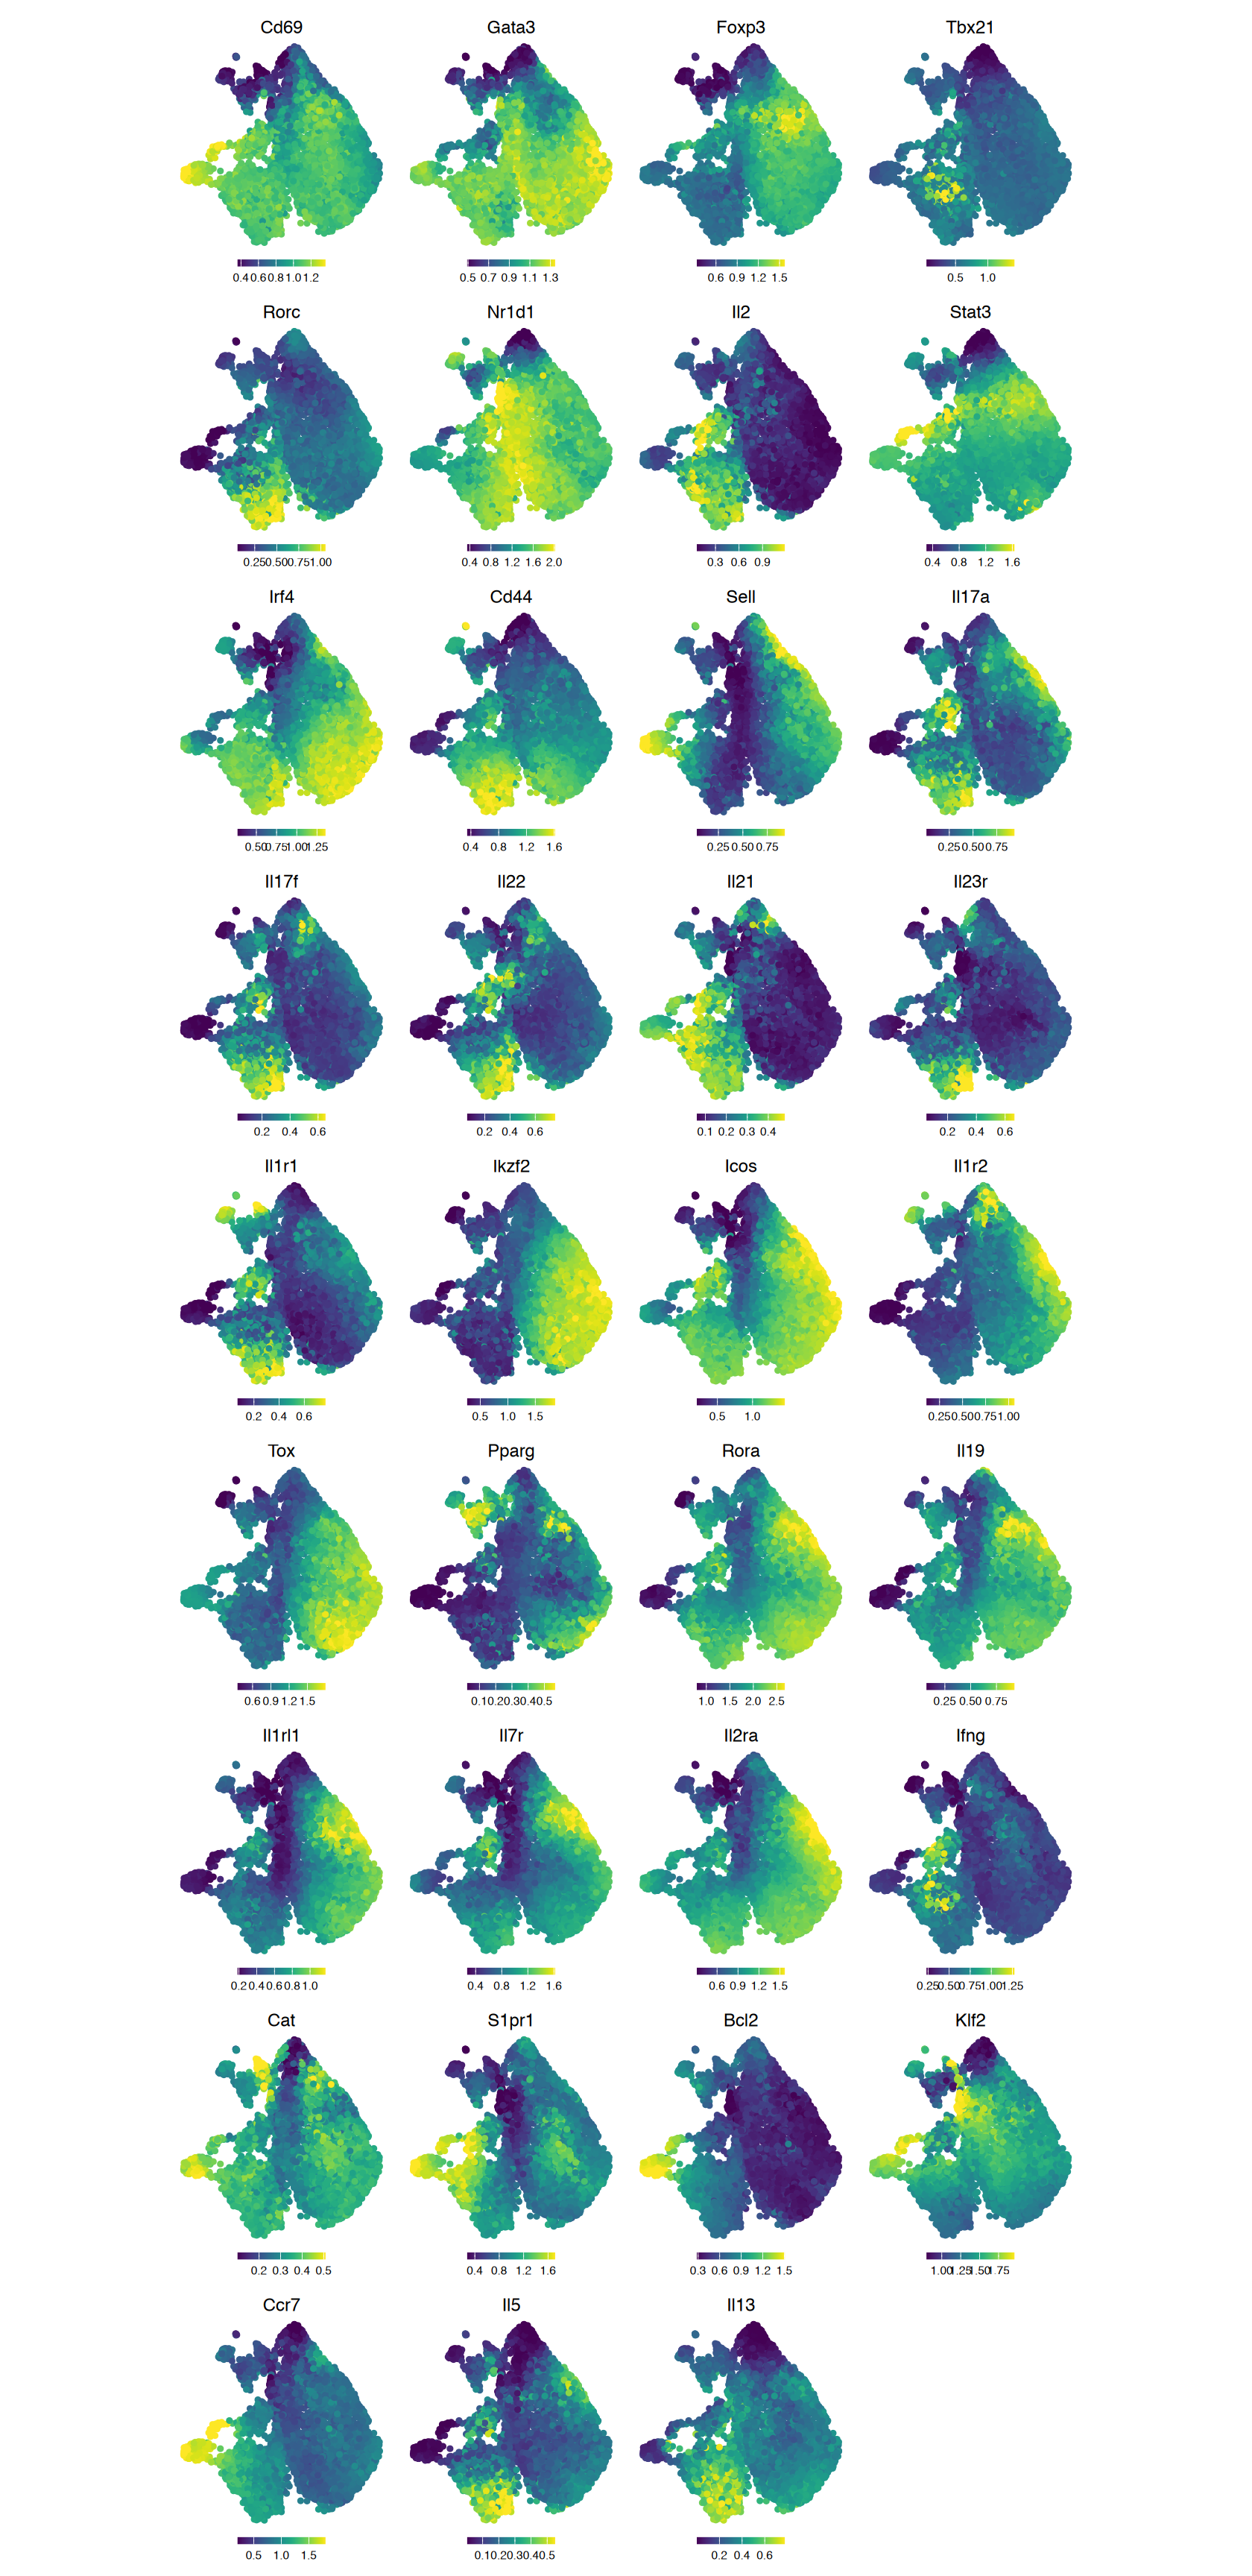

In [11]:
p_markergenes <- plot_identification_genes(markerGenes, "Marker_genes_imputed")


Getting ImputeWeights

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-1e72203d8dc9-Date-2026-10-25_Time-16-48-18.01151.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-10-25 16:48:18.279932 : 

1 
2 


Imputing Matrix

Using weights on disk

1 of 1

Using weights on disk

1 of 1

Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-1e72203d8dc9-Date-2026-10-25_Time-16-48-18.01151.log



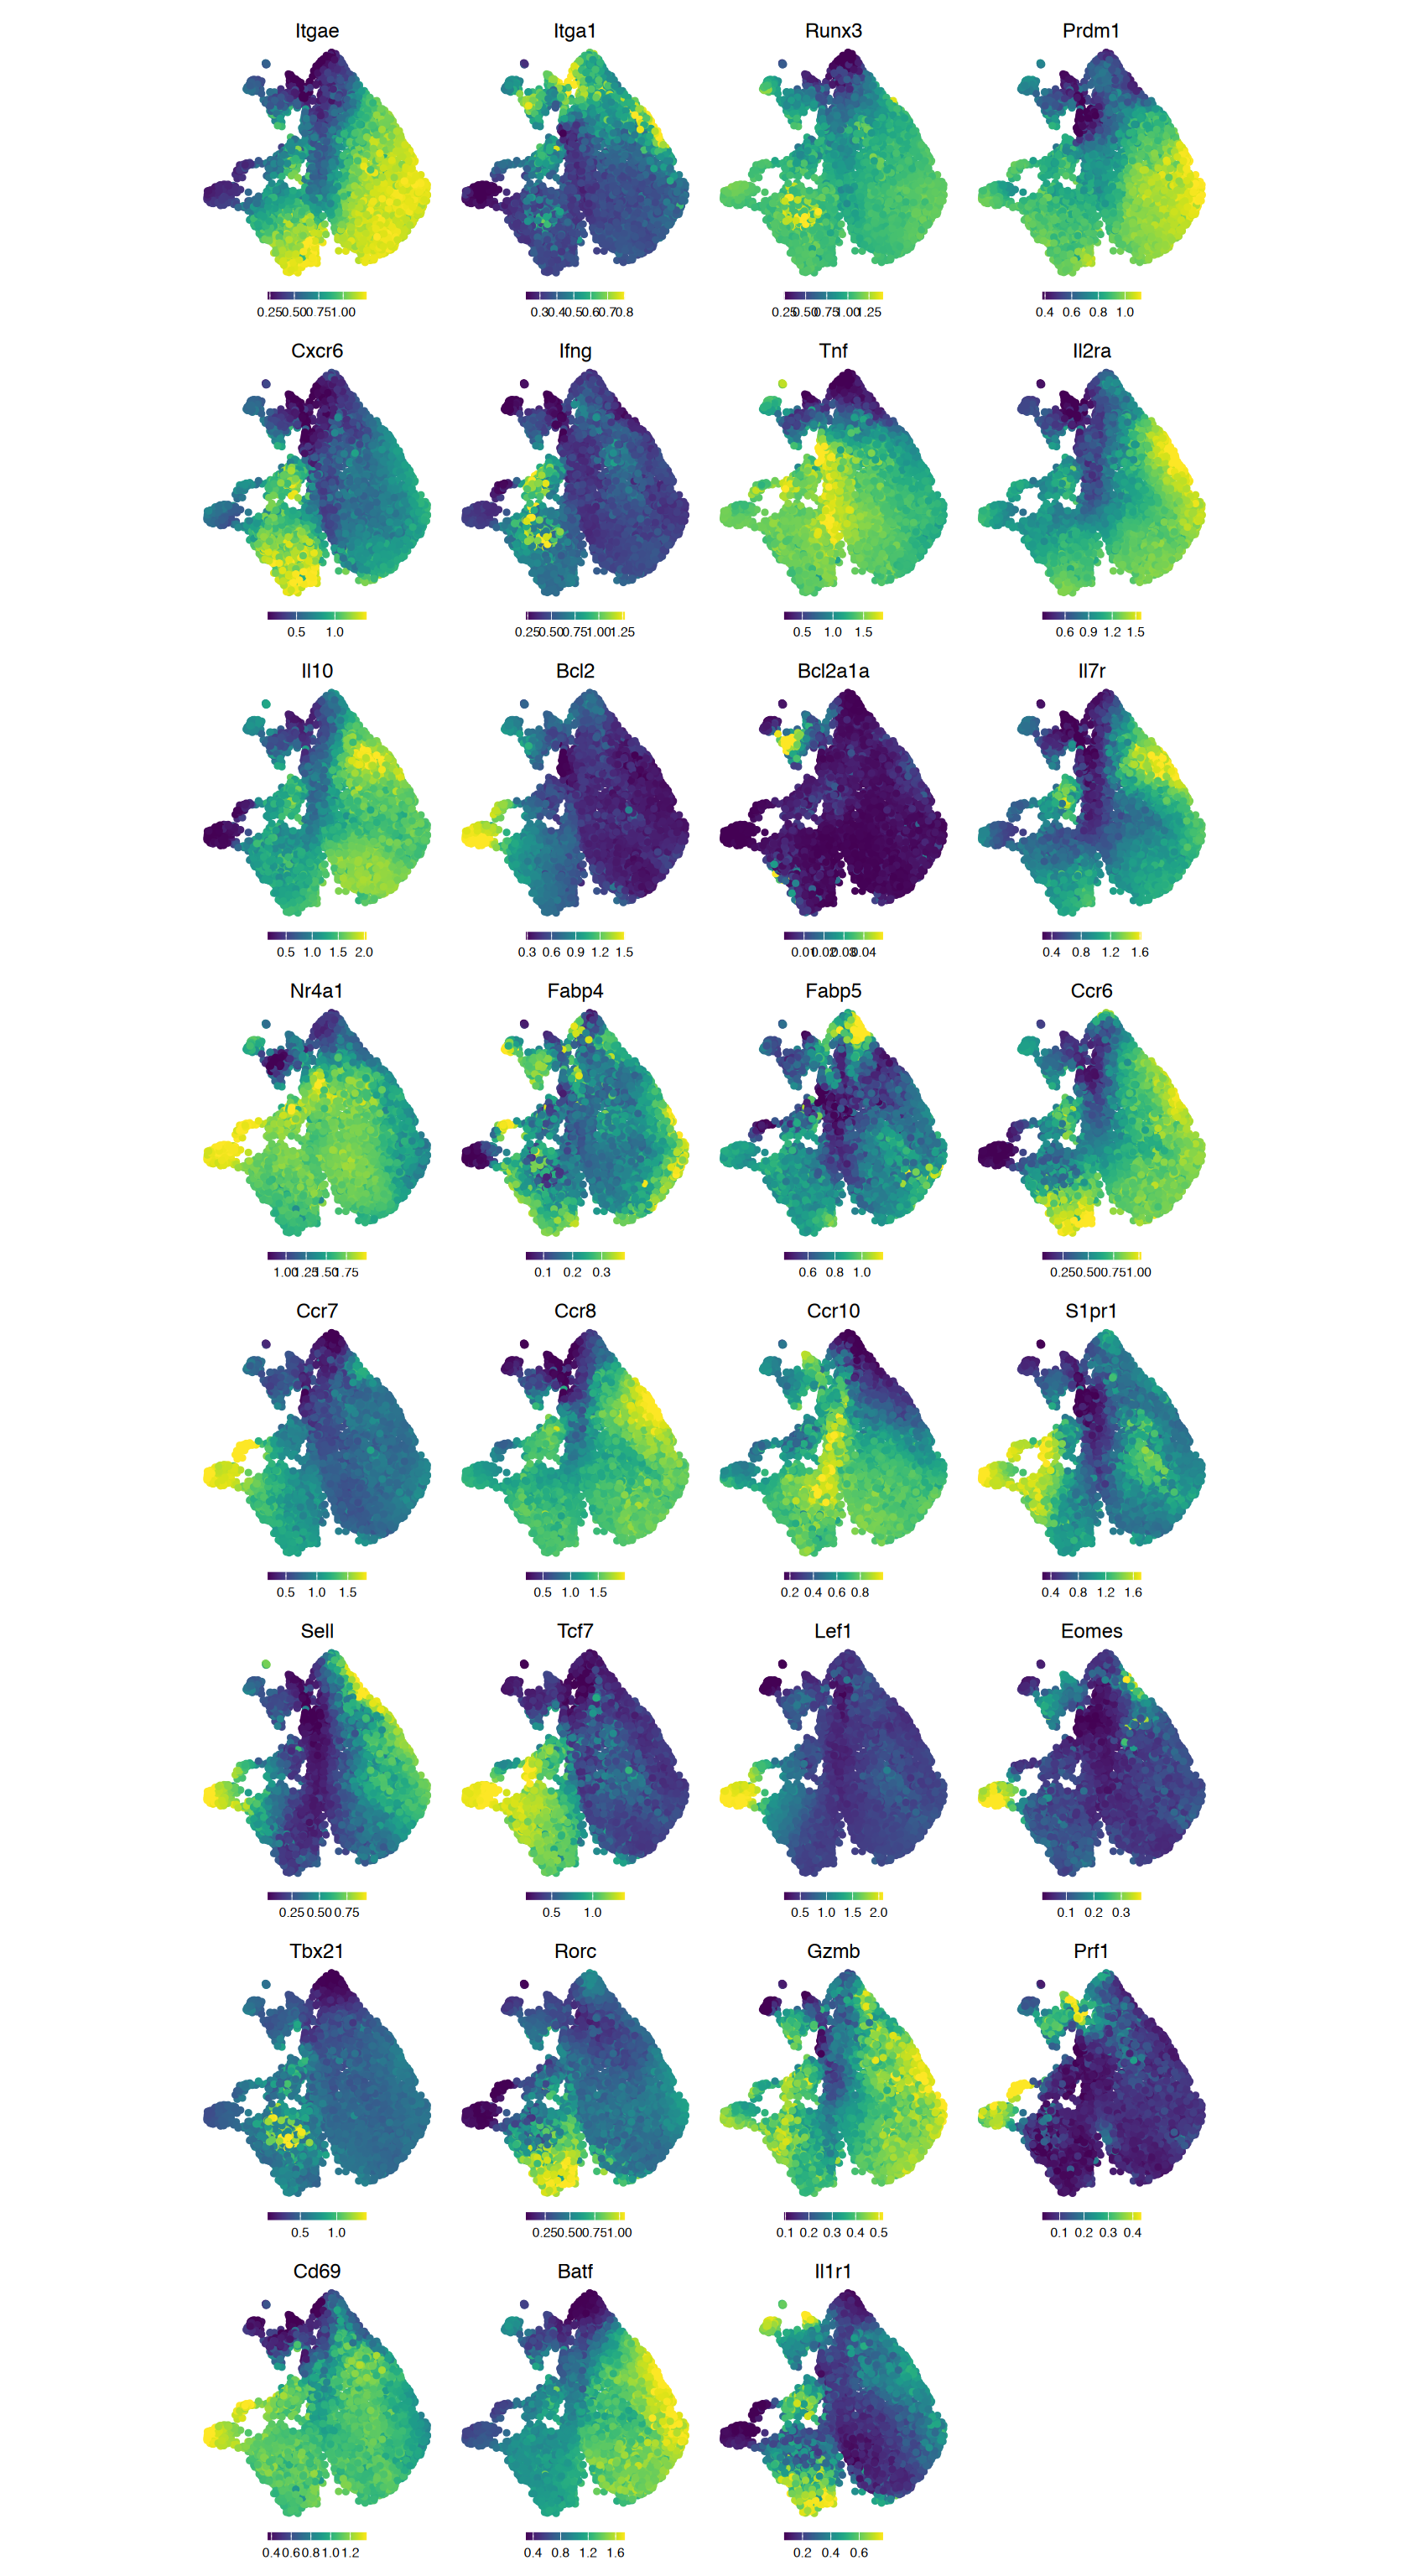

In [12]:
p_additionalgenes <- plot_identification_genes(additionalGenes, "Additional_genes_imputed")


## Calculate top 10 markers per cluster

Rank markers by Log2FC, using FDR <= 0.01 and Log2FC >= 1.


In [13]:
top_marker_tables <- lapply(names(genes_all_clusters), function(cluster) {
    cluster_data <- as.data.frame(genes_all_clusters[[cluster]])
    selected <- which(cluster_data$FDR <= 0.01 & cluster_data$Log2FC >= 1)
    selected <- head(selected[order(cluster_data$Log2FC[selected], decreasing = TRUE)], 10)
    top <- cluster_data[selected, , drop = FALSE]
    data.frame(cluster = rep(cluster, nrow(top)), rank = seq_len(nrow(top)), top,
        row.names = NULL)
})
names(top_marker_tables) <- names(genes_all_clusters)
top_markers_per_cluster <- lapply(top_marker_tables, function(x) x$name)
write.csv(do.call(rbind, top_marker_tables),
    file.path(marker_dir, "top10_markers_per_cluster.csv"), row.names = FALSE)
top_markers_per_cluster


$C1
 [1] "Cd33"     "Pfpl"     "Tas2r143" "Gm57215"  "Ocstamp"  "Gm48065" 
 [7] "Gm2848"   "Ccl3"     "Gm14041"  "Mfsd7a"  

$C2
 [1] "Gm5150" "Unc5c"  "Cntn6"  "Recql5" "Cntn4"  "Lrfn5"  "Lrp1b"  "Wdr64" 
 [9] "Egfem1" "Gpc5"  

$C3
character(0)

$C4
[1] "Macrod2" "Pcdh15"  "Lsamp"  

$C5
 [1] "Trav13-5" "Gm16131"  "Gm42939"  "Trav15-3" "Hotairm1" "Treml2"  
 [7] "Hoxa1"    "Platr11"  "Gm33337"  "Trav1"   

$C6
character(0)

$C7
 [1] "Myod1"   "Il2"     "Gm12167" "Abcb9"   "Gm12532" "Gm11981" "Gm13412"
 [8] "Gm33104" "Tnfsf8"  "Arid5a" 

$C8
 [1] "Cxcr2"         "Ceacam12"      "Gm38397"       "Fpr1"         
 [5] "Gpld1"         "Gm47381"       "4930480M12Rik" "Rnf165"       
 [9] "Slc19a3"       "Gm3424"       

$C9
[1] "Art2b"         "Gm57204"       "Prps1l1"       "5330439M10Rik"
[5] "Pde2a"        

$C10
[1] "Gm13686" "Gm36913" "Ankrd55" "Zc3h15"  "Myo3b"  

$C11
 [1] "Eno3"          "Pfn1"          "Gm20492"       "Ddit3"        
 [5] "Ddit3"         "Mbd6"          "Gm50336"       "2310026L22Rik"
 [9] "Gm4189"        "Mfsd5"        

$C12
 [1] "Slain1os"      "Gm48923"       "Htr4"          "Hnf4a"        
 [5] "Fut11"         "2310011J03Rik" "Ogfr"          "Ppp4c"        
 [9] "Gm28875"       "Taf9"         

$C13
 [1] "Csf2"          "1700001K19Rik" "Papln"         "Prph"         
 [5] "Ulk3"          "Gm12223"       "Gm56513"       "Gm12120"      
 [9] "Tmem176a"      "Gm43177"      

$C14
 [1] "Hook1"         "9530080O11Rik" "Bhlhe41"       "Frey1"        
 [5] "Aloxe3"        "N6amt1"        "Zfp787"        "Gm36371"      
 [9] "Gm57476"       "Gm16244"      

$C15
 [1] "Or10x4"   "Tmem274"  "Or1j19"   "Cort"     "Vmn1r207" "Gm30692" 
 [7] "Or2ak6"   "Gm26972"  "Zfp488"   "Or1e32"  

$C16
 [1] "Gm44096" "Gas1"    "Gm44117" "Hoxa2"   "Hoxaas2" "Cxxc4"   "Gm15948"
 [8] "Gm14003" "Rnf112"  "Gstm1"  

$C17
[1] "A630014C17Rik"

$C18
 [1] "Ighv9-4"       "Gm43495"       "Pilrb2"        "Or13c7c"      
 [5] "Lim2"          "Gm57199"       "4933426K07Rik" "Gm44151"      
 [9] "Gm39035"       "Tbx21"        

$C19
 [1] "Or13c7c" "P2ry1"   "Gm37035" "Gm47015" "Gm5907"  "Tdrp"    "Gm30513"
 [8] "Gm49224" "Zfp773"  "Vmn2r85"

$C20
[1] "Ist1"  "Cenpj" "Parp4"

$C21
character(0)

$C22
 [1] "Cct8l1"   "Gata5"    "Foxc1"    "Gm12305"  "Srms"     "Siglec15"
 [7] "Gm39336"  "Sec14l3"  "Gm48832"  "Cytip"   

$C23
[1] "Gm57204" "Gm35363" "Gm14453"

$C24
 [1] "Or12j2"        "F2rl2"         "4933405E24Rik" "Gm12223"      
 [5] "Gm56513"       "Or2j6"         "Gm10603"       "Il17f"        
 [9] "Gm15918"       "Il23r"        

$C25
 [1] "Gm43495"       "2810455O05Rik" "Trgv3"         "Gpx2"         
 [5] "1700018A04Rik" "Or13a27"       "Gm11377"       "5033421B08Rik"
 [9] "Gm56754"       "Pilrb2"       

$C26
 [1] "Gm35454"  "Trgv7"    "Psors1c2" "Gm12534"  "Trpd52l3" "Krt28"   
 [7] "Adgrg3"   "Tlx2"     "Csf2"     "Tmem176a"

$C27
 [1] "Lcn5"          "Lcn6"          "Aldh8a1"       "Gm1123"       
 [5] "Wfdc15b"       "Timd4"         "5330413D20Rik" "Wfdc15a"      
 [9] "Cxcr2"         "Gm50024"      

$C28
 [1] "Gm44786"       "Ak9"           "Ocln"          "2610042L04Rik"
 [5] "C030013E06Rik" "Gm47770"       "Tff1"          "Rab7b"        
 [9] "Or1f19"        "Gm13571"      

$C29
character(0)

$C30
 [1] "Gm34331"       "Scand1"        "Cnbd2"         "Gm2044"       
 [5] "E330032C10Rik" "Igf2r"         "Gm16201"       "Fam83g"       
 [9] "Spef1l"        "Gm17749"      

$C31
 [1] "Aoc2"      "Tmprss3"   "Mrgpra3"   "Bglap2"    "Rnf138rt1" "Lhfpl4"   
 [7] "Gm35933"   "C78197"    "Mrgpra2b"  "Iglon5"   

$C32
 [1] "Gm12107"       "Gm29112"       "Slfn2"         "D630024D03Rik"
 [5] "Dreh"          "Gm57371"       "Gm2675"        "Gm44079"      
 [9] "5930438M14Rik" "Nrn1"         

$C33
 [1] "Smim10l2a"     "Gm57390"       "Nrn1"          "Gm30177"      
 [5] "4930455G09Rik" "Gm35933"       "Jmjd4"         "Gm56572"      
 [9] "Ihh"           "Gm26935"

## Merge clusters


The mapping below records the manual merging used for the reported analysis.


In [14]:
final_group_map <- list(
    C1 = "C1", C2 = "C5", C3 = "C6", C4 = c("C2", "C3", "C4"),
    C5 = c("C15", "C16"), C6 = c("C24", "C26"), C7 = c("C17", "C18", "C19"),
    C8 = "C25", C9 = c("C27", "C28", "C29"), C10 = c("C30", "C31", "C32", "C33"),
    C11 = c("C8", "C9", "C10"), C12 = "C7", C13 = c("C12", "C13", "C14"),
    C14 = "C11", C15 = c("C20", "C21", "C22", "C23"))

lookup <- setNames(rep(names(final_group_map), lengths(final_group_map)), unlist(final_group_map, use.names = FALSE))
umap_df$FinalGroup <- factor(unname(lookup[as.character(umap_df$Resolution4Cluster)]), levels = names(final_group_map))
stopifnot(!anyNA(umap_df$FinalGroup))
proj$Resolution4Cluster <- as.character(umap_df$Resolution4Cluster)
proj$FinalGroup <- as.character(umap_df$FinalGroup)
proj$Clusters <- as.character(umap_df$FinalGroup)
proj$C8_vs_Others <- ifelse(proj$FinalGroup == "C8", "C8", "Others")
write.csv(umap_df, file.path(tables_dir, "cells_and_umap.csv"), row.names = FALSE)
counts <- table(umap_df$FinalGroup, umap_df$Sample)
write.csv(as.data.frame.matrix(counts), file.path(tables_dir, "group_counts.csv"))
counts


     
      HFD LFD
  C1   57  34
  C2   83  99
  C3   23  26
  C4  320 234
  C5  186 105
  C6  113 237
  C7  291 301
  C8  208  57
  C9  526  52
  C10 236 667
  C11 443 337
  C12 119 148
  C13 226 327
  C14  70 158
  C15 423 305

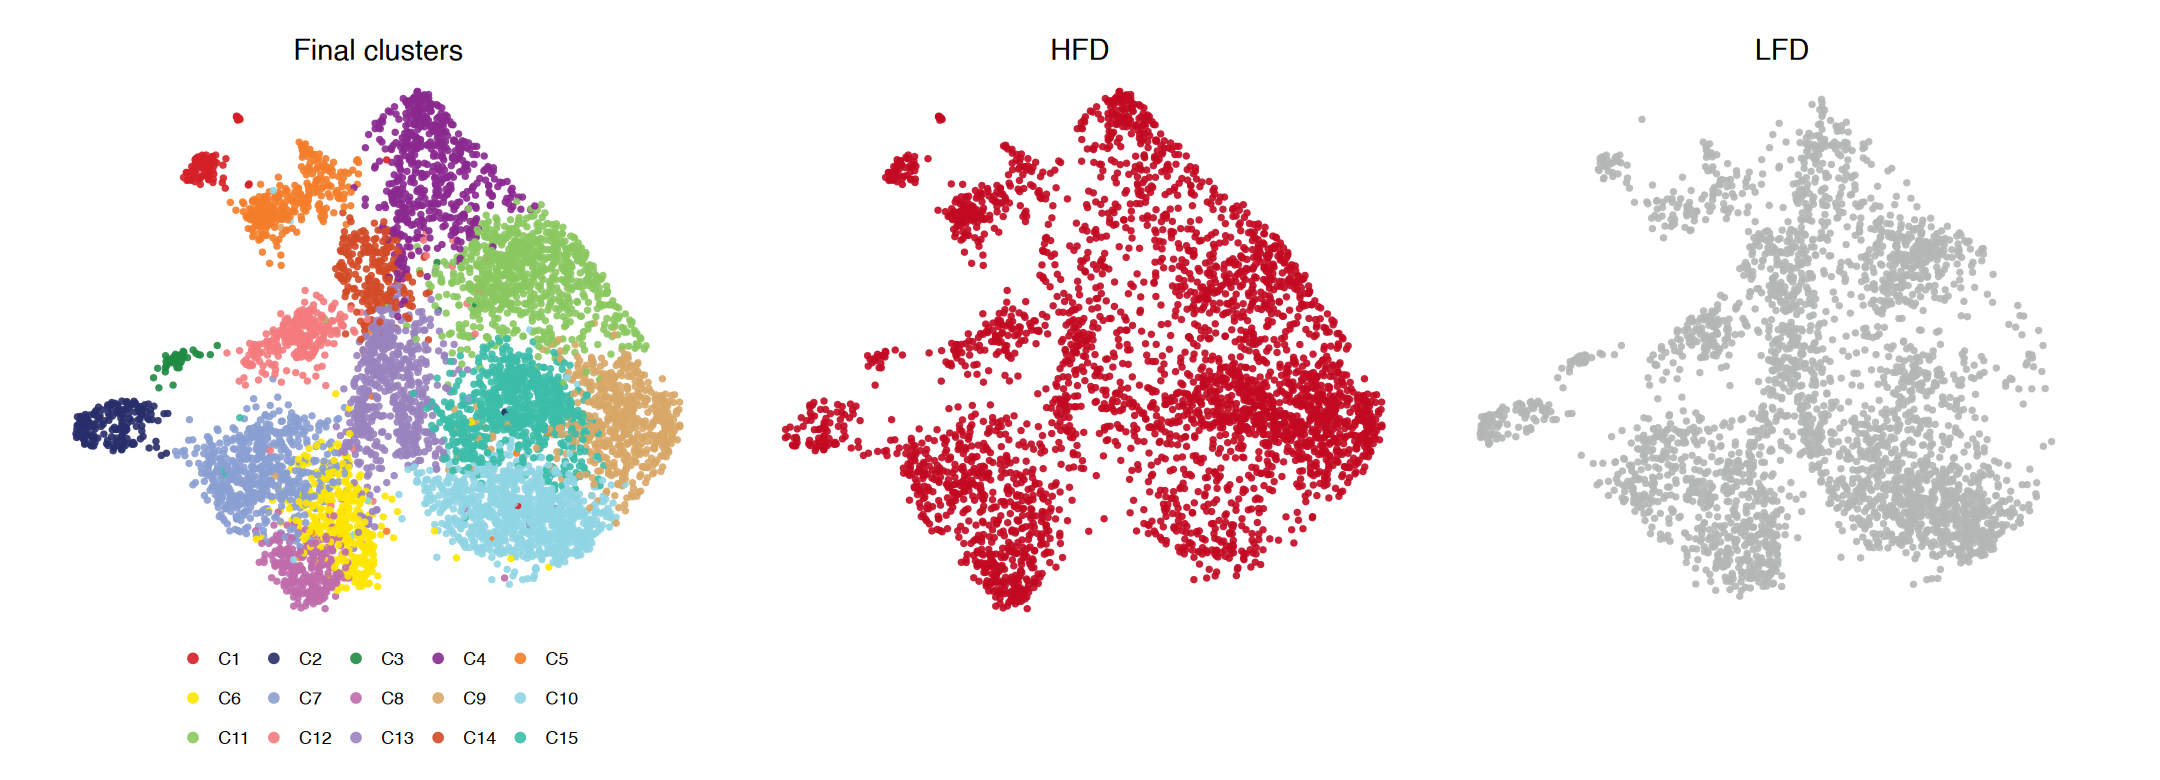

In [15]:
# Final clusters, HFD and LFD
sample_colours <- c(HFD = "#c20922", LFD = "#b3b6b6", C8 = "black")
x_limits <- range(umap_df$UMAP1)
y_limits <- range(umap_df$UMAP2)
p_final <- ggplot(umap_df[plot_order, ], aes(UMAP1, UMAP2, colour = FinalGroup)) +
    geom_point(size = 1.8, alpha = 0.9, stroke = 0) + umap_theme +
    scale_colour_manual(values = paletteDiscrete(names(final_group_map), set = "stallion")) +
    coord_equal(xlim = x_limits, ylim = y_limits) + labs(title = "Final clusters") +
    guides(colour = guide_legend(nrow = 3, byrow = TRUE, override.aes = list(size = 3)))
sample_plots <- lapply(c("HFD", "LFD"), function(sample_name) {
    ggplot(umap_df[umap_df$Sample == sample_name, ], aes(UMAP1, UMAP2)) +
        geom_point(size = 1.8, alpha = 0.9, stroke = 0, colour = sample_colours[[sample_name]]) +
        coord_equal(xlim = x_limits, ylim = y_limits) + umap_theme + labs(title = sample_name)
})
final_panel <- wrap_plots(c(list(p_final), sample_plots), ncol = 3)
options(repr.plot.width = 18, repr.plot.height = 6.5)
print(final_panel)
save_plot(final_panel, "Clusters_HFD_LFD", file.path(figure_dir, "umap"), 18, 6.5)


## Imputed gene scores


In [16]:
# Add imputation weights
RNGkind("Mersenne-Twister", "Inversion", "Rejection")
proj <- addImputeWeights(proj, reducedDims = "IterativeLSI", td = 3, ka = 4,
    sampleCells = 5000, nRep = 2, k = 15, epsilon = 1, threads = 1, seed = 1)
marker_genes <- c("Klf2", "Cd69", "Itgae", "Runx3", "Hlf", "Bhlhe40", "Rbpj")
set.seed(42)
gene_plots <- plotEmbedding(proj, colorBy = "GeneScoreMatrix", name = marker_genes,
    embedding = "UMAP", imputeWeights = getImputeWeights(proj), quantCut = c(0.01, 0.99),
    log2Norm = TRUE, plotAs = "points", rastr = FALSE, size = 1.5,
    pal = viridisLite::viridis(256), threads = 1, force = TRUE)


ArchR logging to : ArchRLogs/ArchR-addImputeWeights-1e72655ec8a2-Date-2026-10-25_Time-16-48-54.476197.log
If there is an issue, please report to github with logFile!

2026-10-25 16:48:54.583071 : Computing Impute Weights Using Magic (Cell 2018), 0 mins elapsed.

Getting ImputeWeights

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-1e7231c637ac-Date-2026-10-25_Time-16-49-04.290392.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-10-25 16:49:06.261365 : 

1 
2 


Imputing Matrix

Using weights on disk

1 of 1

Using weights on disk

1 of 1

Plotting Embedding

1 
2 
3 
4 
5 
6 
7 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-1e7231c637ac-Date-2026-10-25_Time-16-49-04.290392.log



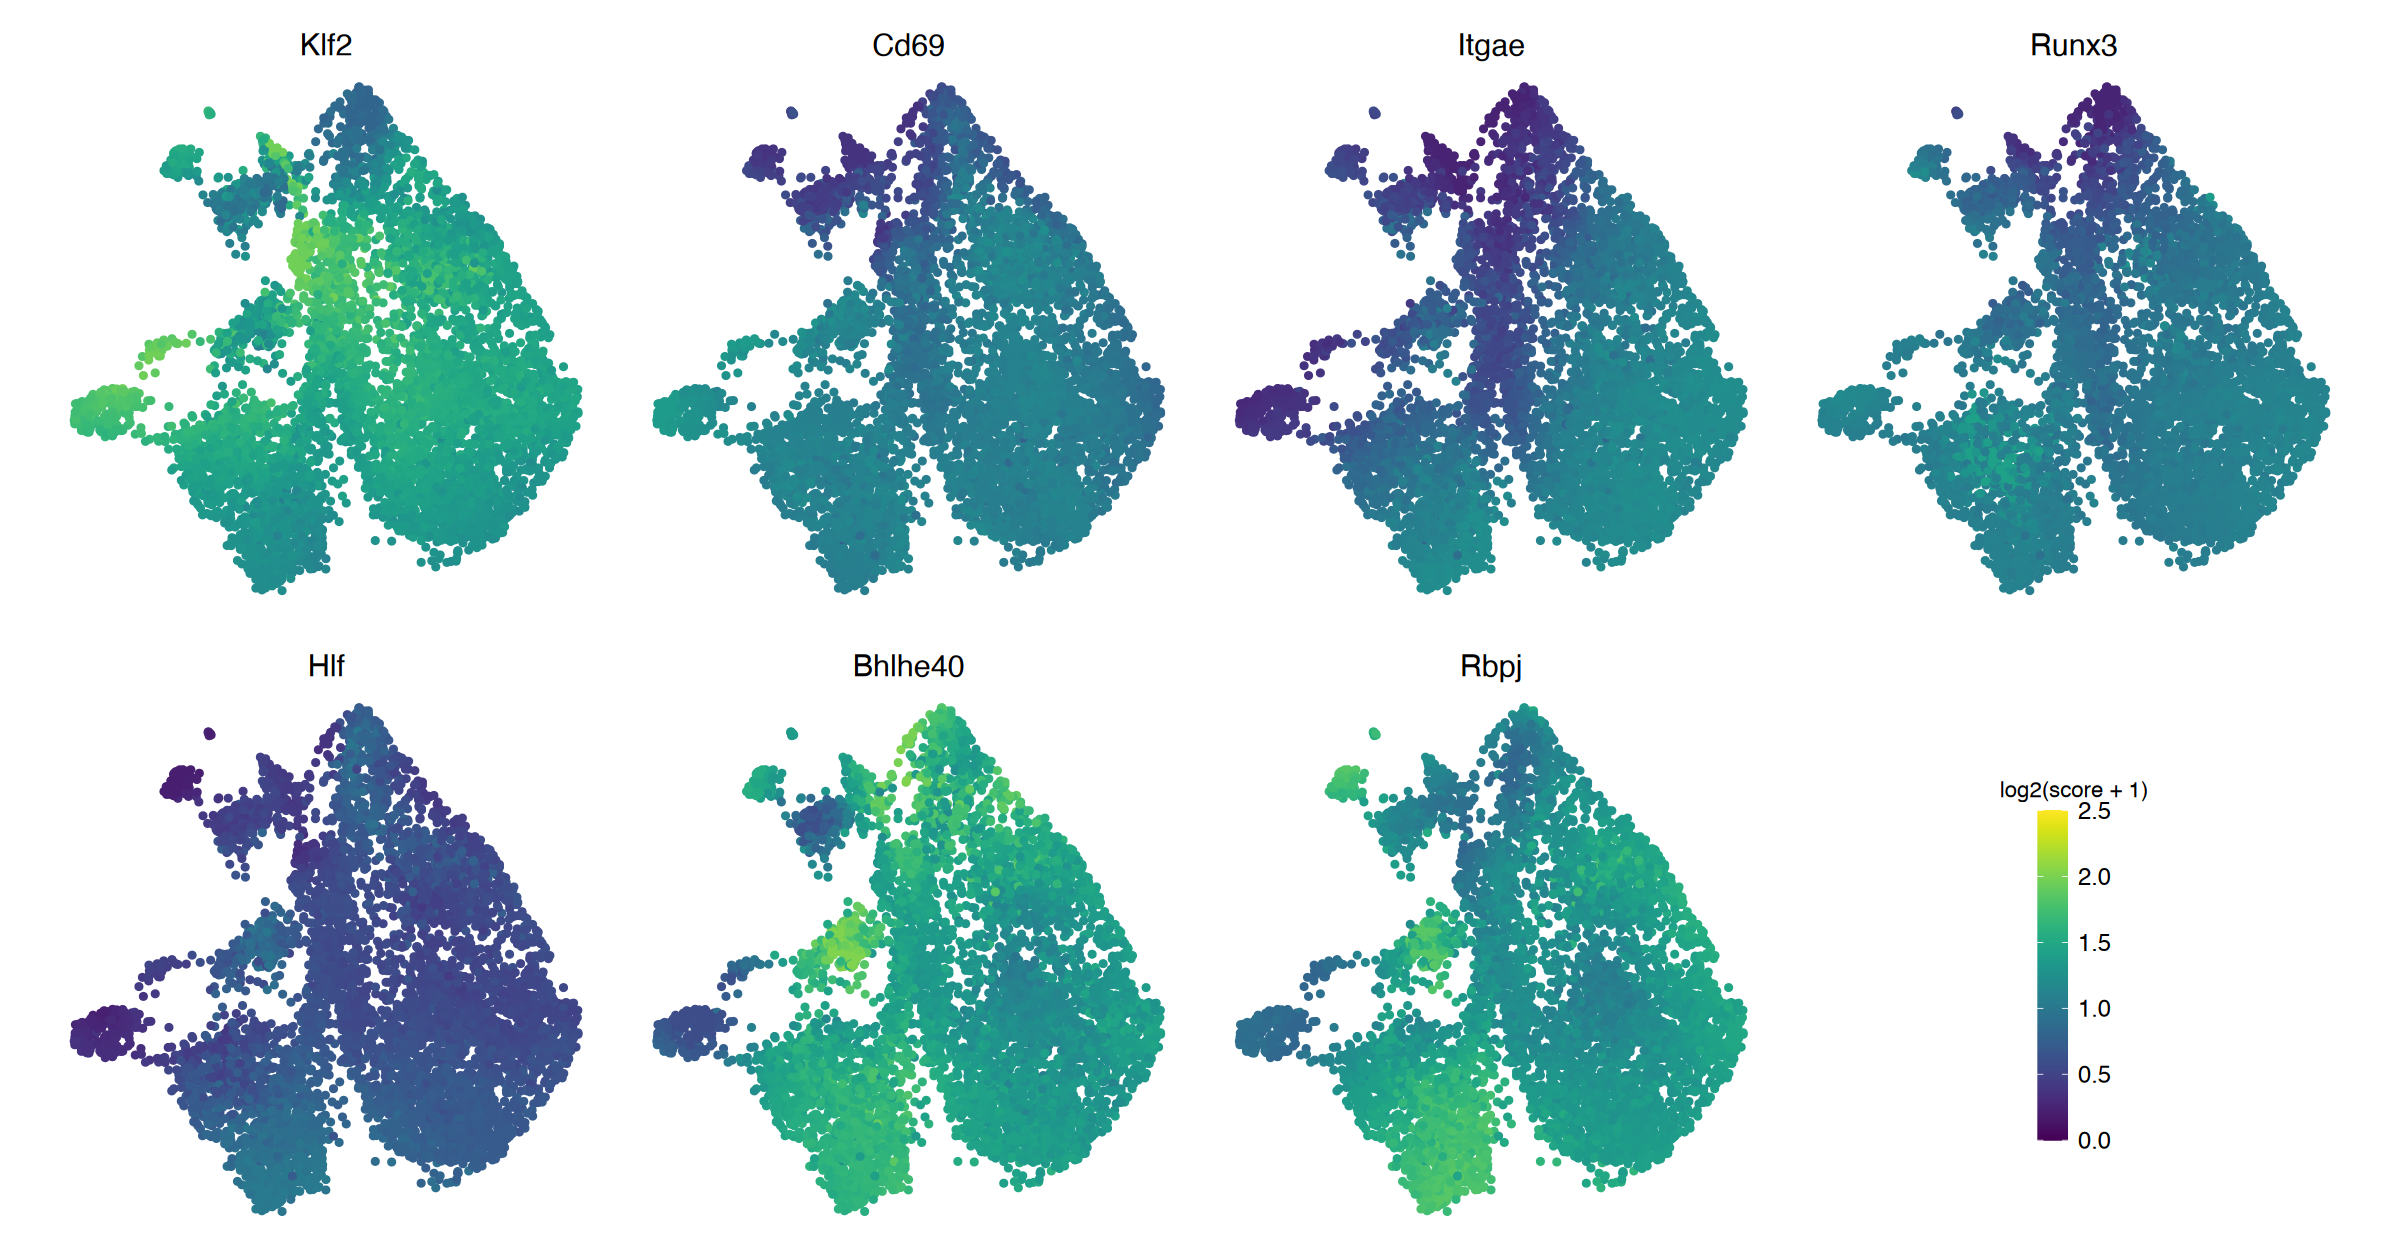

In [17]:
# Shared scale and original viridis colours
gene_score_values <- list()
for (gene in marker_genes) {
    p <- gene_plots[[gene]]
    index <- as.integer(rownames(p$data))
    gene_score_values[[gene]] <- data.frame(cell_id = getCellNames(proj)[index], gene = gene,
        UMAP1 = p$data$x, UMAP2 = p$data$y, imputed_colour = p$data$color)
    p$scales$scales <- list()
    gene_plots[[gene]] <- p +
        scale_colour_gradientn(colours = viridisLite::viridis(256), limits = c(0, 2.5),
            breaks = seq(0, 2.5, 0.5), name = "log2(score + 1)") +
        labs(title = gene) + theme_void(base_size = 12) + theme(
            plot.title = element_text(size = 18, face = "italic", hjust = 0.5),
            legend.position = "right", legend.direction = "vertical",
            legend.text = element_text(size = 14), legend.title = element_text(size = 13),
            plot.margin = margin(3, 3, 3, 3, unit = "mm")) +
        guides(colour = guide_colourbar(direction = "vertical", title.position = "top",
            title.hjust = 0.5, barwidth = grid::unit(0.65, "cm"), barheight = grid::unit(7, "cm")))
    save_plot(gene_plots[[gene]], paste0(gene, "_imputed"), file.path(figure_dir, "gene_scores"), 6, 6)
}
gene_panel <- wrap_plots(c(gene_plots, list(guide_area())), ncol = 4, guides = "collect")
options(repr.plot.width = 20, repr.plot.height = 10.5)
print(gene_panel)
save_plot(gene_panel, "Imputed_gene_scores", file.path(figure_dir, "gene_scores"), 20, 10.5)
write.csv(do.call(rbind, gene_score_values), file.path(tables_dir, "imputed_gene_scores.csv"), row.names = FALSE)


## C6, C7 and C8


In [18]:
# Calculate the selected density outlines
zoom_cells <- umap_df[umap_df$FinalGroup %in% c("C6", "C7", "C8"), ]
bandwidth <- c(bandwidth.nrd(zoom_cells$UMAP1), bandwidth.nrd(zoom_cells$UMAP2))
limits <- c(range(zoom_cells$UMAP1) + c(-1, 1) * 2 * bandwidth[1],
    range(zoom_cells$UMAP2) + c(-1, 1) * 2 * bandwidth[2])
density_outline <- function(cells, group, masses, smoothing = 1) {
    kde <- kde2d(cells$UMAP1, cells$UMAP2, h = bandwidth * smoothing, n = 300, lims = limits)
    values <- sort(as.vector(kde$z), decreasing = TRUE)
    paths <- list()
    for (mass in masses) {
        threshold <- values[which(cumsum(values) / sum(values) >= mass)[1]]
        lines <- contourLines(kde$x, kde$y, kde$z, levels = threshold)
        for (j in seq_along(lines)) paths[[length(paths) + 1]] <- data.frame(
            x = lines[[j]]$x, y = lines[[j]]$y, group = group, mass = mass,
            bandwidth_multiplier = smoothing, path = paste(group, mass, smoothing, j, sep = "_"))
    }
    do.call(rbind, paths)
}
sample_outlines <- do.call(rbind, lapply(c("LFD", "HFD"), function(sample_name)
    density_outline(zoom_cells[zoom_cells$Sample == sample_name, ], sample_name, c(0.4, 0.7))))
c8_outline <- density_outline(zoom_cells[zoom_cells$FinalGroup == "C8", ], "C8", 0.4, 0.7)
zoom_x <- range(c(zoom_cells$UMAP1, sample_outlines$x, c8_outline$x))
zoom_y <- range(c(zoom_cells$UMAP2, sample_outlines$y, c8_outline$y))
write.csv(rbind(sample_outlines, c8_outline), file.path(tables_dir, "C6_C7_C8_contours.csv"), row.names = FALSE)
table(droplevels(zoom_cells$FinalGroup), zoom_cells$Sample)


    
     HFD LFD
  C6 113 237
  C7 291 301
  C8 208  57

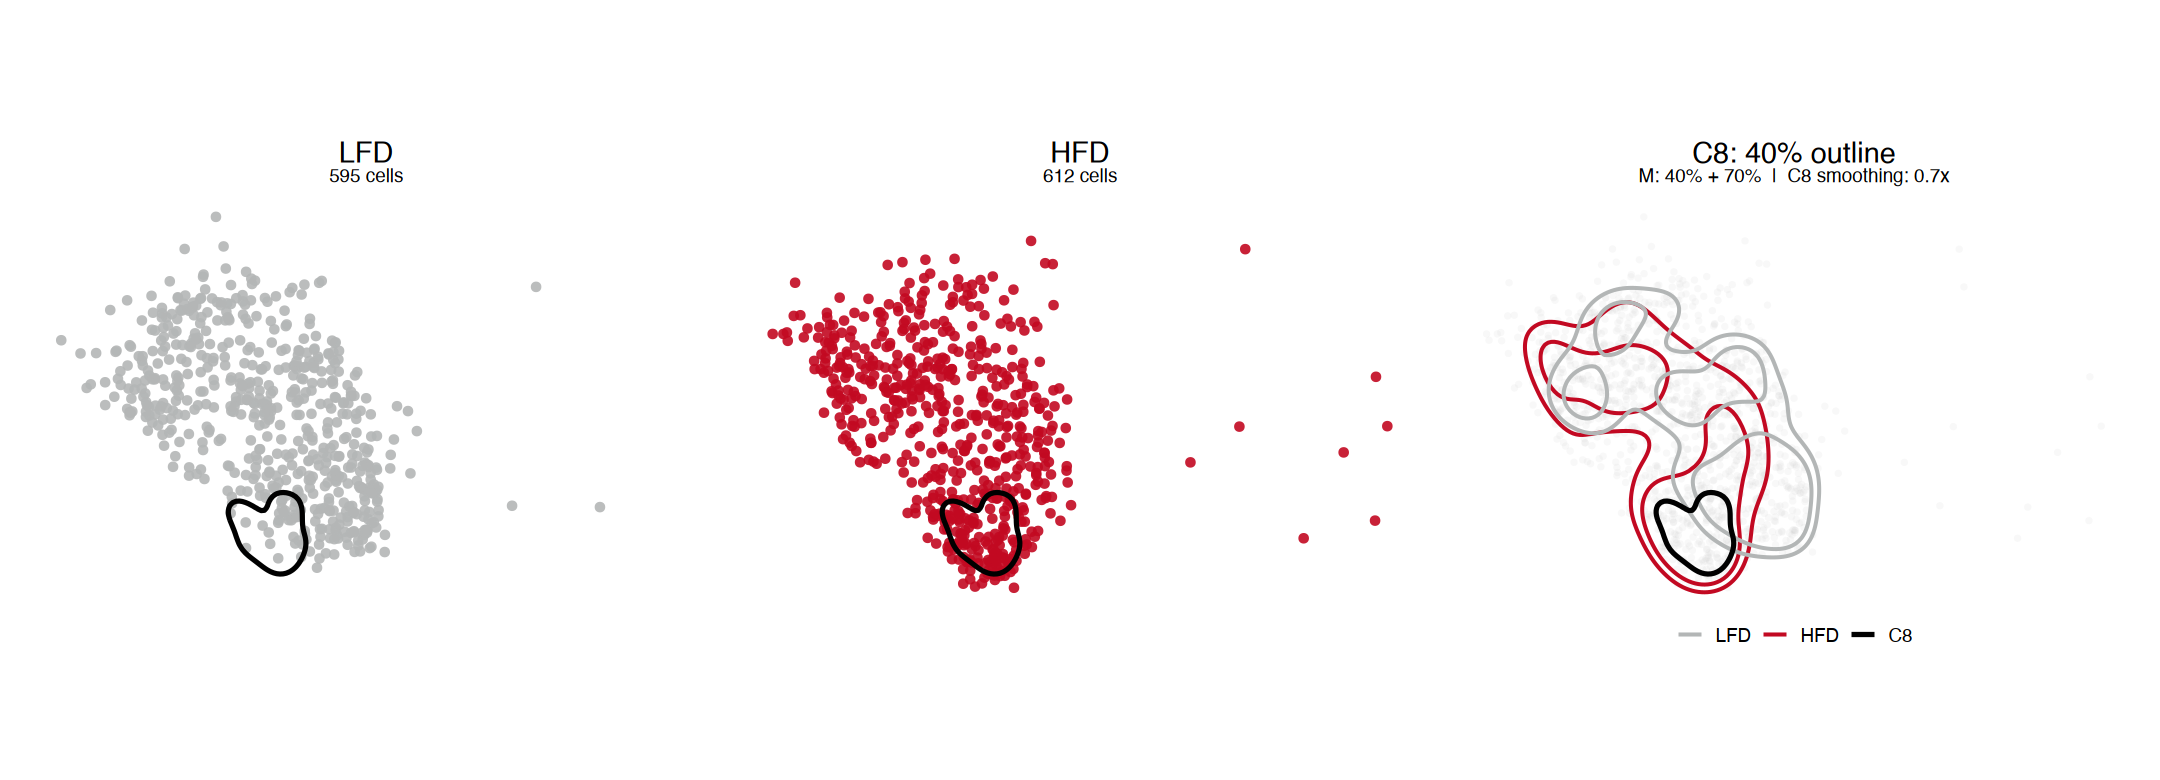

In [19]:
# LFD, HFD and M contours with larger dots
zoom_theme <- umap_theme + theme(legend.text = element_text(size = 11),
    plot.subtitle = element_text(size = 11, hjust = 0.5, margin = margin(b = 8)))
zoom_plots <- lapply(c("LFD", "HFD"), function(sample_name) {
    d <- zoom_cells[zoom_cells$Sample == sample_name, ]
    ggplot(d, aes(UMAP1, UMAP2)) +
        geom_point(size = 2.7, alpha = 0.9, stroke = 0, colour = sample_colours[[sample_name]]) +
        geom_path(data = c8_outline, aes(x, y, group = path), inherit.aes = FALSE,
            colour = "black", linewidth = 1.1) +
        coord_equal(xlim = zoom_x, ylim = zoom_y) + zoom_theme +
        labs(title = sample_name, subtitle = paste(nrow(d), "cells"))
})
p_density <- ggplot(zoom_cells, aes(UMAP1, UMAP2)) +
    geom_point(size = 1.8, alpha = 0.12, stroke = 0, colour = "#c9c9c9") +
    geom_path(data = sample_outlines, aes(x, y, group = path, colour = group),
        inherit.aes = FALSE, linewidth = 0.85) +
    geom_path(data = c8_outline, aes(x, y, group = path, colour = group),
        inherit.aes = FALSE, linewidth = 1.1) +
    scale_colour_manual(values = sample_colours, breaks = c("LFD", "HFD", "C8")) +
    coord_equal(xlim = zoom_x, ylim = zoom_y) + zoom_theme +
    labs(title = "C8: 40% outline", subtitle = "M: 40% + 70%  |  C8 smoothing: 0.7x")
zoom_panel <- wrap_plots(c(zoom_plots, list(p_density)), ncol = 3)
options(repr.plot.width = 18, repr.plot.height = 6.5)
print(zoom_panel)
zoom_folder <- file.path(figure_dir, "C6_C7_C8")
save_plot(zoom_panel, "LFD_HFD_M_C8_mass40_bw070", zoom_folder, 18, 6.5)
for (i in seq_along(zoom_plots)) save_plot(zoom_plots[[i]], c("LFD", "HFD")[i], zoom_folder, 6, 6)
save_plot(p_density, "M_C8_mass40_bw070", zoom_folder, 6, 6)


## Genome browser tracks: C8 versus all other cells

Fragment-start occupancy, normalized per 10,000 ReadsInTSS. 200 bp bins,
400 bp Gaussian smoothing; shared y-axis within each gene. Promoters:
1,000 bp upstream and 100 bp downstream of this gene's annotated transcript TSS.


In [20]:
# Track settings
track_genes <- c("Il1r1", "Il23r", "Hlf", "Il21", "Ccl20", "Tnfsf4", "Ikzf2", "Tox", "Il6st")
browser_dir <- file.path(figure_dir, "browser_tracks")
coverage_dir <- file.path(browser_dir, "coverage_data")
dir.create(coverage_dir, recursive = TRUE, showWarnings = FALSE)
cell_ids <- getCellNames(proj)
cell_groups <- setNames(as.character(proj$C8_vs_Others), cell_ids)
cell_samples <- setNames(as.character(proj$Sample), cell_ids)
denominators <- tapply(as.numeric(proj$ReadsInTSS), cell_groups, sum)
tile_bp <- 200L
weights <- dnorm(seq(-6L, 6L) * tile_bp, sd = 400)
weights <- weights / sum(weights)
track_colours <- c(C8 = "#FF321E", Others = "#1D2866")


In [21]:
# Read and smooth the browser signal
browser_signal <- function(gene, left, right) {
    chromosome <- as.character(seqnames(gene))
    chromosome_length <- as.numeric(seqlengths(gene)[chromosome])
    padding_left <- max(1L, floor((left - 2400L) / tile_bp) * tile_bp)
    padding_right <- min(chromosome_length, ceiling((right + 2400L) / tile_bp) * tile_bp)
    region <- GRanges(chromosome, IRanges(padding_left, padding_right))
    tile_left <- seq(floor(padding_left / tile_bp), floor(padding_right / tile_bp) + 1L) * tile_bp
    counts <- matrix(0, length(tile_left), 2, dimnames = list(NULL, c("C8", "Others")))
    for (sample_name in names(arrow_files)) {
        fragments <- getFragmentsFromArrow(ArrowFile = arrow_files[[sample_name]], chr = chromosome,
            cellNames = cell_ids[cell_samples == sample_name], verbose = FALSE)
        fragments <- subsetByOverlaps(fragments, region, ignore.strand = TRUE)
        cell_index <- match(as.character(fragments$RG), cell_ids)
        stopifnot(!anyNA(cell_index))
        bins <- match(floor(start(fragments) / tile_bp) * tile_bp, tile_left, nomatch = 0L)
        keep <- bins > 0L & !duplicated(data.frame(tile = bins, cell = cell_index))
        for (group in c("C8", "Others")) counts[, group] <- counts[, group] +
            tabulate(bins[keep & cell_groups[cell_index] == group], nbins = length(tile_left))
    }
    plot_x <- sort(unique(c(left, seq(left, right, by = 50L), right)))
    coverage <- curves <- list()
    for (group in c("C8", "Others")) {
        normalized <- counts[, group] * 10000 / denominators[[group]]
        smoothed <- as.numeric(stats::filter(normalized, weights, sides = 2))
        coverage[[group]] <- data.frame(x = tile_left + (tile_bp - 1) / 2,
            bin_start = tile_left, bin_end = tile_left + tile_bp - 1L,
            count = counts[, group], raw = normalized, smoothed = smoothed, group = group,
            denominator_ReadsInTSS = denominators[[group]])
        finite <- is.finite(smoothed)
        curves[[group]] <- data.frame(x = plot_x,
            y = approx(coverage[[group]]$x[finite], smoothed[finite], xout = plot_x)$y, group = group)
    }
    list(coverage = do.call(rbind, coverage), curve = do.call(rbind, curves))
}


In [22]:
# Draw the gene model and tracks
make_track_panel <- function(curve, window, promoters, y_max) {
    gene <- window$gene
    left <- window$left
    right <- window$right
    curve$group <- factor(curve$group, levels = c("C8", "Others"))
    hi <- as.data.frame(promoters)
    hi$start <- pmax(hi$start, left)
    hi$end <- pmin(hi$end, right)
    hi <- hi[hi$start <= hi$end, , drop = FALSE]
    exons <- gene_annotation$exons[which(gene_annotation$exons$gene_id == gene$gene_id)]
    exons <- as.data.frame(exons)
    exons$start <- pmax(exons$start, left)
    exons$end <- pmin(exons$end, right)
    exons <- exons[exons$start <= exons$end, , drop = FALSE]
    positive <- as.character(strand(gene)) == "+"
    gene_colour <- if (positive) "#E9302A" else "#3C84BD"
    gene_left <- max(start(gene), left)
    gene_right <- min(end(gene), right)
    visible_width <- gene_right - gene_left
    mid <- seq(gene_left + visible_width * 0.15, gene_right - visible_width * 0.15, length.out = 5L)
    arrow_end <- mid + if (positive) (right - left) * 0.006 else -(right - left) * 0.006
    note <- if (window$view == "Full locus") "" else window$view
    model <- ggplot2::ggplot() +
        ggplot2::annotate("segment", x = gene_left, xend = gene_right, y = 0.32, yend = 0.32,
            linewidth = 0.55, colour = gene_colour) +
        ggplot2::geom_rect(data = exons, ggplot2::aes(xmin = start, xmax = end, ymin = 0.18, ymax = 0.46),
            fill = gene_colour, colour = NA) +
        ggplot2::annotate("segment", x = mid, xend = arrow_end, y = 0.32, yend = 0.32,
            linewidth = 0.4, colour = gene_colour,
            arrow = grid::arrow(length = grid::unit(0.06, "inches"), type = "open")) +
        ggplot2::annotate("text", x = left, y = 0.86, label = window$symbol,
            fontface = "italic", size = 5, hjust = 0, vjust = 0.5) +
        ggplot2::annotate("text", x = right, y = 0.86,
            label = sprintf("C8: %s cells  |  Others: %s cells", sum(cell_groups == "C8"), format(sum(cell_groups == "Others"), big.mark = ",")), size = 2.7, colour = "#555555", hjust = 1) +
        ggplot2::annotate("text", x = (left + right) / 2, y = 0.85,
            label = note, size = 2.5, colour = "#555555") +
        ggplot2::scale_x_continuous(limits = c(left, right), expand = c(0, 0)) +
        ggplot2::scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
        ggplot2::theme_void() + ggplot2::theme(plot.margin = ggplot2::margin(3, 8, 0, 5))
    y_label <- "Fragment-start occupancy\n(per 10,000 ReadsInTSS)"
    bulk <- ggplot2::ggplot(curve, ggplot2::aes(x = x, y = y, fill = group)) +
        ggplot2::geom_rect(data = hi, ggplot2::aes(xmin = start, xmax = end, ymin = 0, ymax = y_max),
            inherit.aes = FALSE, fill = "#DCECDF", colour = NA) +
        ggplot2::geom_area(stat = "identity", position = "identity", colour = NA) +
        ggplot2::facet_wrap(~group, ncol = 1, strip.position = "right", scales = "fixed") +
        ggplot2::scale_fill_manual(values = track_colours, guide = "none") +
        ggplot2::scale_x_continuous(limits = c(left, right),
            breaks = pretty(c(left, right), n = 4),
            labels = function(x) format(x / 1000, trim = TRUE, scientific = FALSE, big.mark = ","),
            expand = c(0, 0)) +
        ggplot2::scale_y_continuous(limits = c(0, y_max), breaks = c(0, y_max / 2, y_max),
            labels = function(x) format(signif(x, 3), scientific = FALSE, trim = TRUE), expand = c(0, 0)) +
        ggplot2::labs(x = paste0("mm39 · ", as.character(seqnames(gene)), " position (kb)"), y = y_label) +
        ggplot2::theme_classic(base_size = 10) +
        ggplot2::theme(panel.spacing = grid::unit(1, "lines"),
            panel.border = ggplot2::element_rect(fill = NA, linewidth = 0.4),
            strip.background = ggplot2::element_rect(fill = "#F0F0F0", colour = "black", linewidth = 0.4),
            strip.text = ggplot2::element_text(size = 11, margin = ggplot2::margin(3, 5, 3, 5)),
            axis.line = ggplot2::element_blank(), axis.ticks = ggplot2::element_line(linewidth = 0.3),
            axis.text = ggplot2::element_text(colour = "black", size = 9),
            plot.margin = ggplot2::margin(1, 8, 4, 5))
    ggplot2::ggplotGrob(cowplot::plot_grid(plotlist = list(model, bulk), ncol = 1,
        rel_heights = c(1.1, 5), align = "v", axis = "lr"))
}


ArchR logging to : ArchRLogs/ArchR-getFragmentsFromArrow-1e724c7c3ae4-Date-2026-10-25_Time-16-49-32.201379.log
If there is an issue, please report to github with logFile!

ArchR logging to : ArchRLogs/ArchR-getFragmentsFromArrow-1e726ffe75f6-Date-2026-10-25_Time-16-49-33.871412.log
If there is an issue, please report to github with logFile!

ArchR logging to : ArchRLogs/ArchR-getFragmentsFromArrow-1e722af2a2eb-Date-2026-10-25_Time-16-49-35.496912.log
If there is an issue, please report to github with logFile!

ArchR logging to : ArchRLogs/ArchR-getFragmentsFromArrow-1e721fa60854-Date-2026-10-25_Time-16-49-37.749604.log
If there is an issue, please report to github with logFile!

ArchR logging to : ArchRLogs/ArchR-getFragmentsFromArrow-1e724d6cd307-Date-2026-10-25_Time-16-49-39.495491.log
If there is an issue, please report to github with logFile!

ArchR logging to : ArchRLogs/ArchR-getFragmentsFromArrow-1e7223929847-Date-2026-10-25_Time-16-49-41.929349.log
If there is an issue, please 

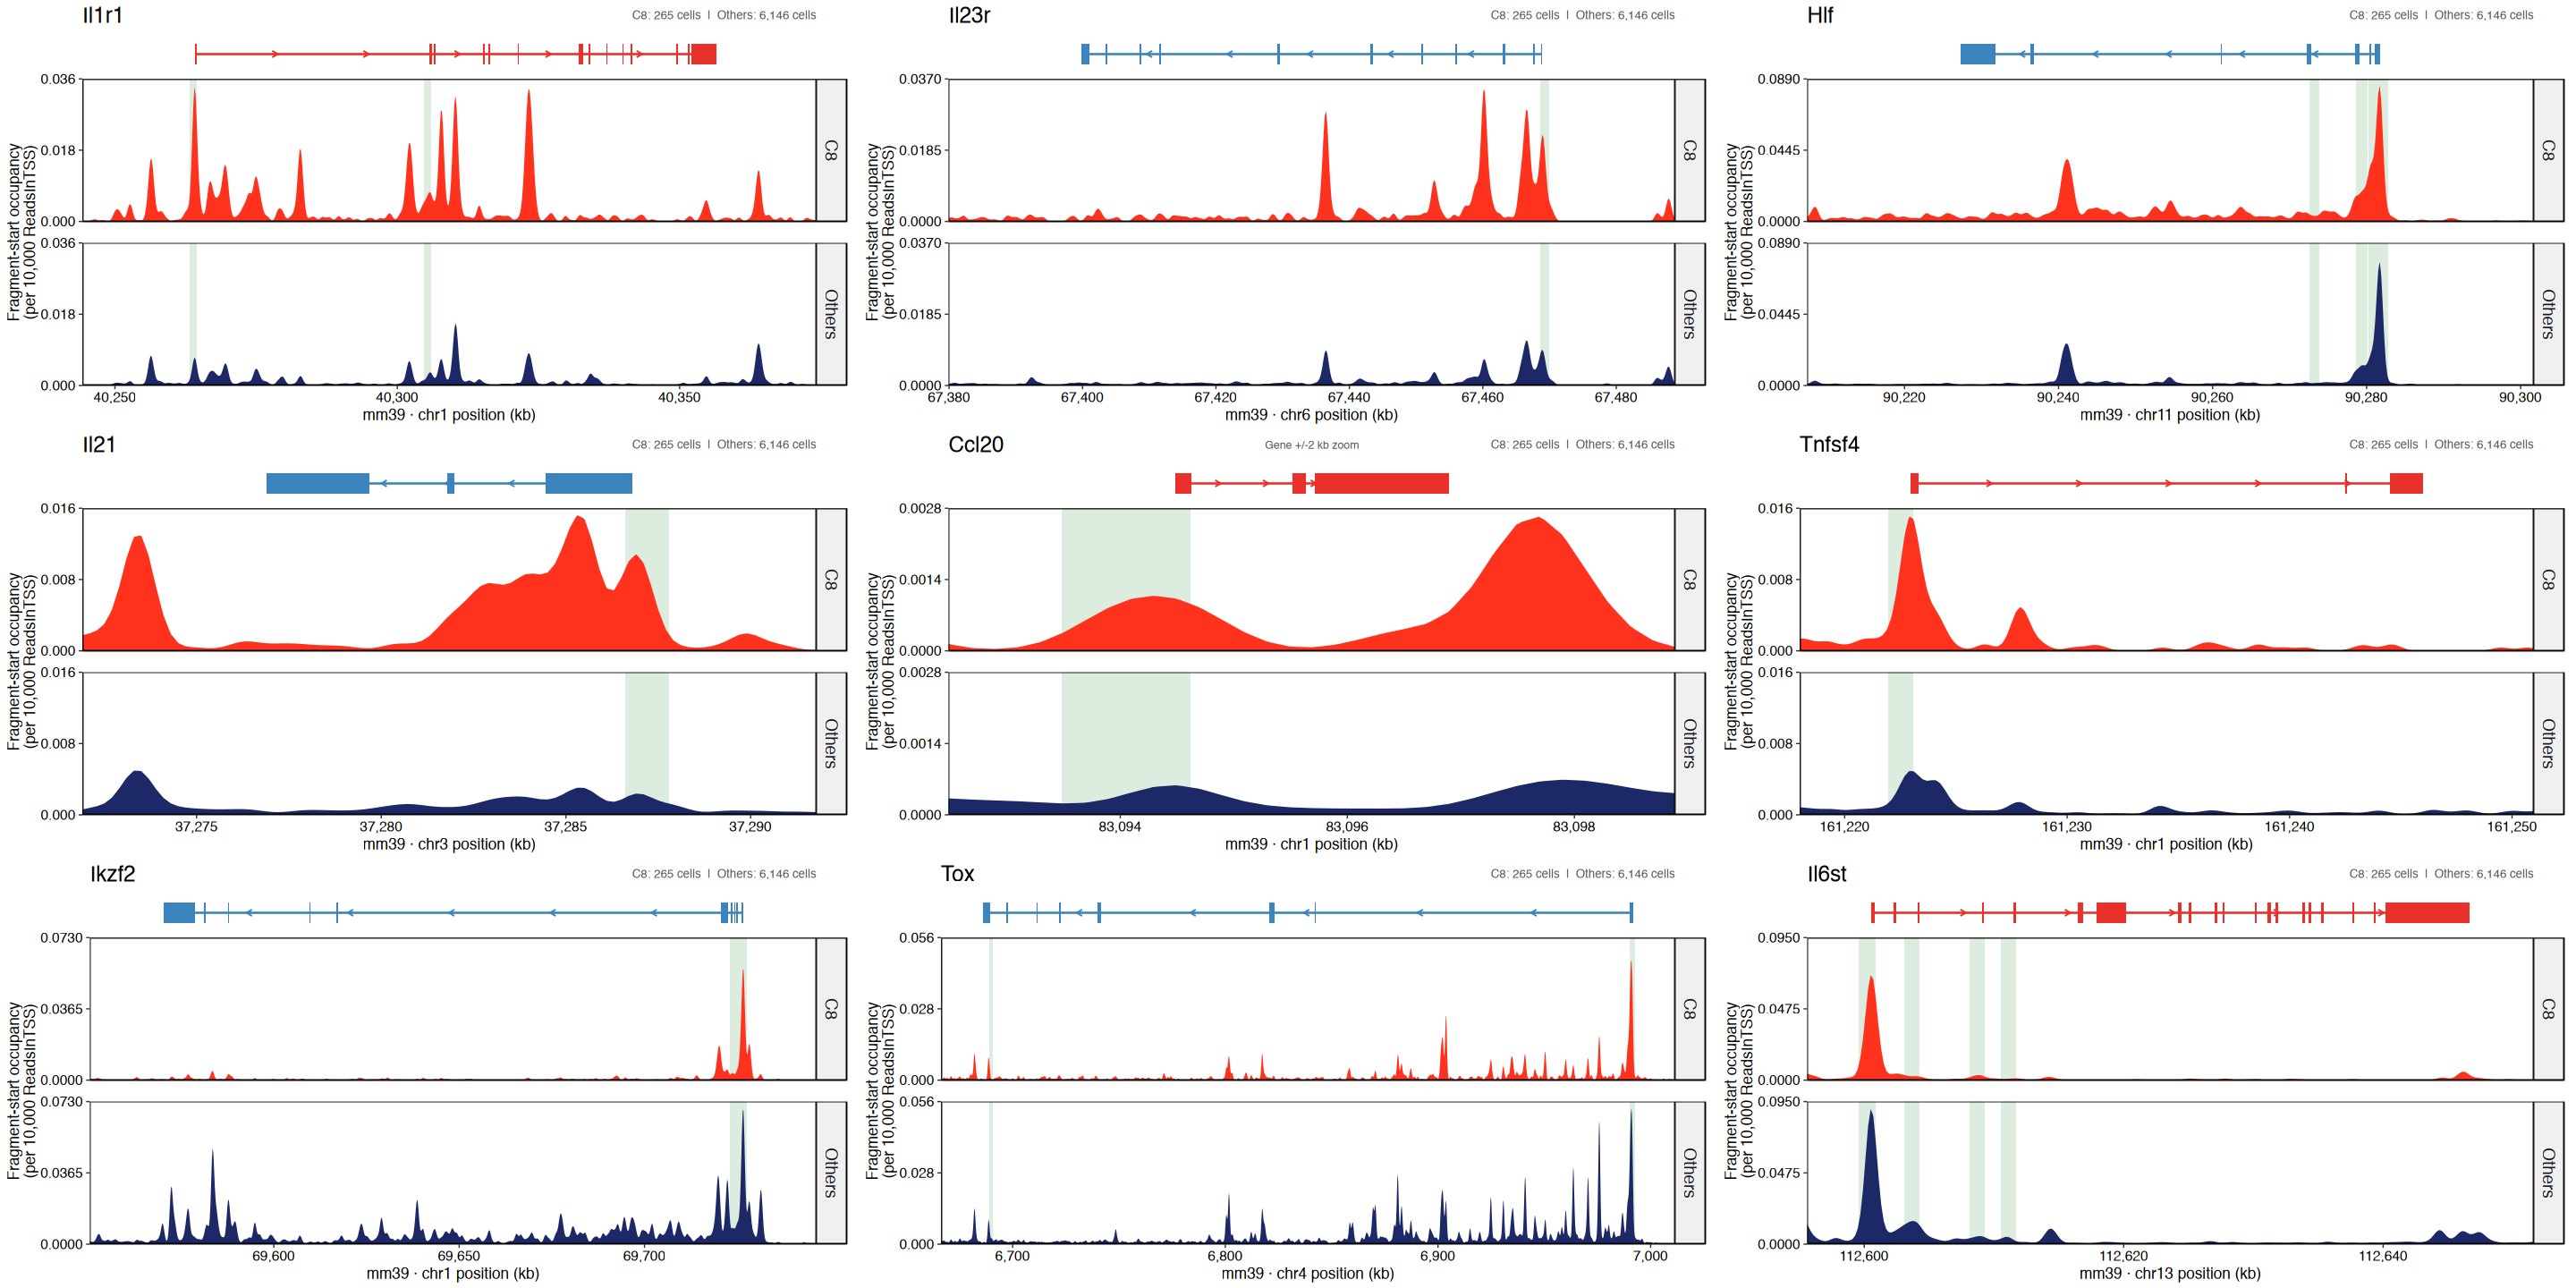

In [23]:
# Plot all nine genes
browser_plots <- list()
for (symbol in track_genes) {
    gene <- genes[genes$symbol == symbol]
    stopifnot(length(gene) == 1L)
    flank <- if (symbol %in% c("Il21", "Tnfsf4", "Il6st")) 5000L else 20000L
    if (symbol == "Ccl20") flank <- 2000L
    left <- start(gene) - flank
    right <- end(gene) + flank
    if (symbol == "Il1r1") right <- start(gene) + 110000L
    left <- max(1L, left)
    right <- min(as.numeric(seqlengths(gene)[as.character(seqnames(gene))]), right)
    tx <- transcript_annotation[transcript_annotation$gene_id == gene$gene_id]
    promoter_regions <- reduce(trim(promoters(unique(resize(tx, 1L, fix = "start")),
        upstream = 1000L, downstream = 100L)), ignore.strand = TRUE)
    signal <- browser_signal(gene, left, right)
    max_y <- max(signal$curve$y)
    rounding <- if (max_y > 0) 10^(floor(log10(max_y * 1.05)) - 1L) else 1
    y_max <- if (max_y > 0) ceiling(max_y * 1.05 / rounding) * rounding else 1
    window <- list(gene = gene, symbol = symbol, left = left, right = right,
        view = if (symbol == "Ccl20") "Gene +/-2 kb zoom" else "Full locus")
    browser_plots[[symbol]] <- make_track_panel(signal$curve, window, promoter_regions, y_max)
    save_plot(browser_plots[[symbol]], paste0(symbol, "_C8_vs_Others"), browser_dir, 8, 4)
    write.csv(signal$coverage, file.path(coverage_dir, paste0(symbol, "_coverage.csv")), row.names = FALSE)
    write.csv(signal$curve, file.path(coverage_dir, paste0(symbol, "_plotted_curve.csv")), row.names = FALSE)
}
browser_panel <- gridExtra::arrangeGrob(grobs = browser_plots, ncol = 3)
options(repr.plot.width = 24, repr.plot.height = 12)
grid::grid.newpage()
grid::grid.draw(browser_panel)
save_plot(browser_panel, "All_9_genes", browser_dir, 24, 12)
writeLines(capture.output(sessionInfo()), file.path(output_dir, "sessionInfo.txt"))
